In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset bawaan Seaborn
tips = sns.load_dataset("tips")

# Tampilkan 5 baris pertama
print("=== 5 Data Pertama ===")
print(tips.head())

=== 5 Data Pertama ===
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


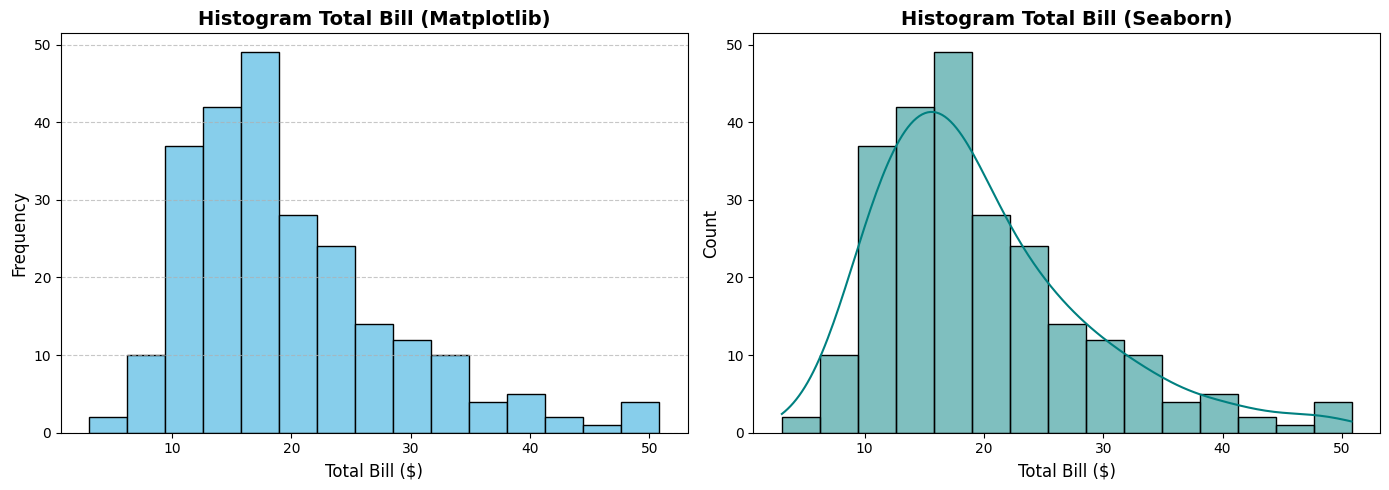

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Matplotlib
axes[0].hist(tips['total_bill'], bins=15, color='skyblue', edgecolor='black')
axes[0].set_title('Histogram Total Bill (Matplotlib)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Total Bill ($)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# 2. Seaborn
sns.histplot(data=tips, x='total_bill', bins=15, kde=True, color='teal', ax=axes[1])
axes[1].set_title('Histogram Total Bill (Seaborn)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Bill ($)', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)

plt.tight_layout()
plt.show()

/tmp/ipykernel_396/3240441384.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tips, x='day', y='total_bill', palette='Set2', errorbar=None, ax=axes[1])


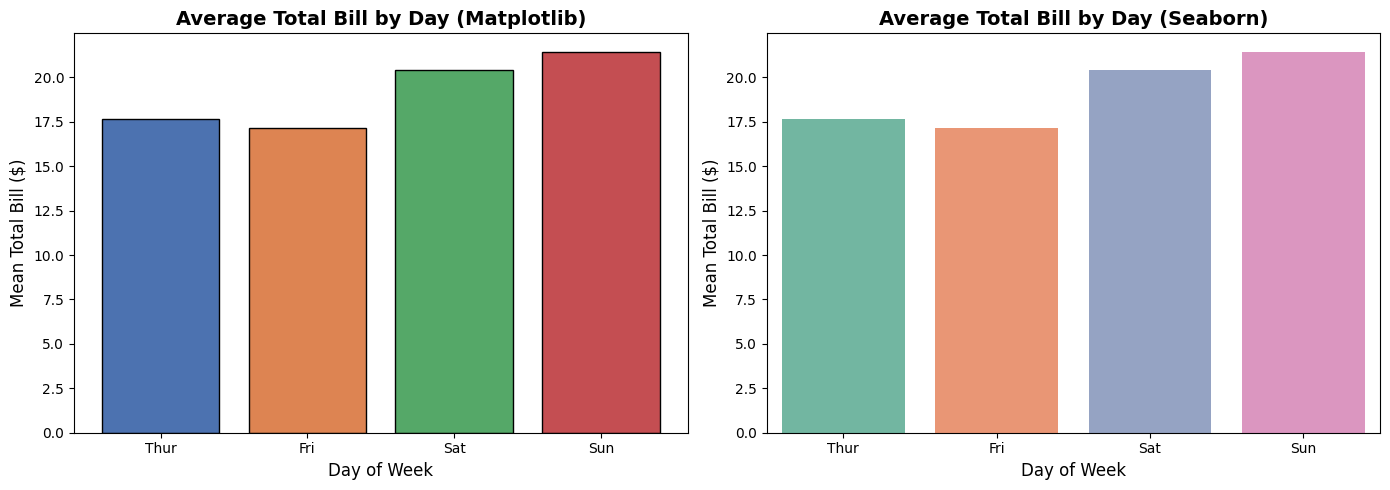

In [ ]:
# Hitung rata-rata untuk Matplotlib
avg_bill = tips.groupby('day', observed=False)['total_bill'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Matplotlib
axes[0].bar(avg_bill.index, avg_bill.values, color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'], edgecolor='black')
axes[0].set_title('Average Total Bill by Day (Matplotlib)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Day of Week', fontsize=12)
axes[0].set_ylabel('Mean Total Bill ($)', fontsize=12)

# 2. Seaborn
sns.barplot(data=tips, x='day', y='total_bill', palette='Set2', errorbar=None, ax=axes[1])
axes[1].set_title('Average Total Bill by Day (Seaborn)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Day of Week', fontsize=12)
axes[1].set_ylabel('Mean Total Bill ($)', fontsize=12)

plt.tight_layout()
plt.show()

/tmp/ipykernel_396/649452494.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(data_by_day, labels=days, patch_artist=True,
/tmp/ipykernel_396/649452494.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tips, x='day', y='total_bill', palette='Pastel1', ax=axes[1])


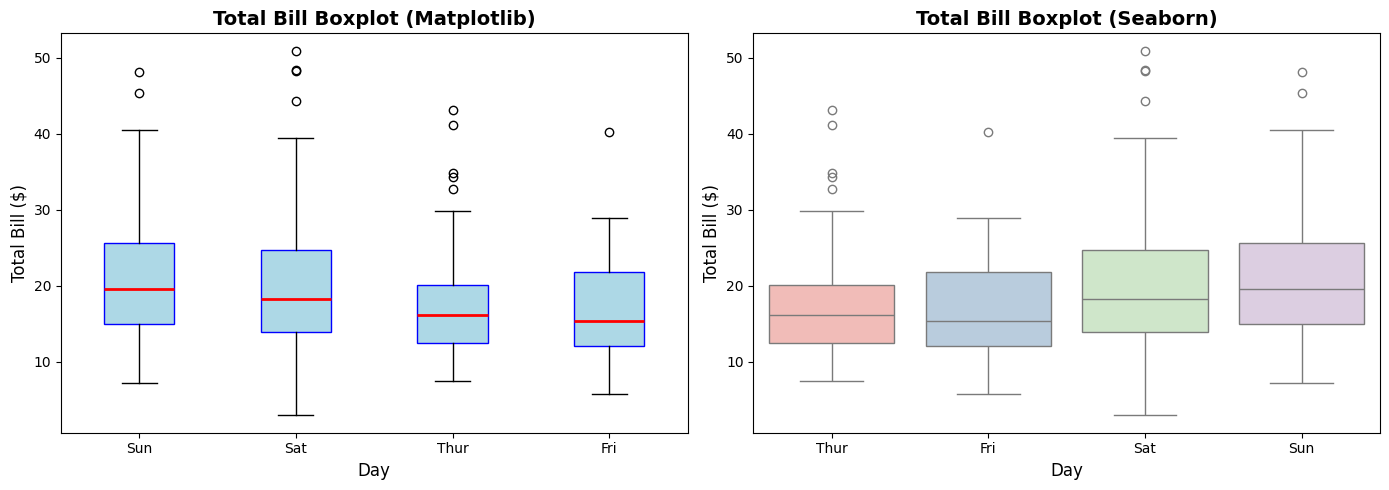

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Persiapkan data per hari untuk Matplotlib
days = tips['day'].unique()
data_by_day = [tips[tips['day'] == day]['total_bill'] for day in days]

# 1. Matplotlib
axes[0].boxplot(data_by_day, labels=days, patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='blue'),
                medianprops=dict(color='red', linewidth=2))
axes[0].set_title('Total Bill Boxplot (Matplotlib)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Day', fontsize=12)
axes[0].set_ylabel('Total Bill ($)', fontsize=12)

# 2. Seaborn
sns.boxplot(data=tips, x='day', y='total_bill', palette='Pastel1', ax=axes[1])
axes[1].set_title('Total Bill Boxplot (Seaborn)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Day', fontsize=12)
axes[1].set_ylabel('Total Bill ($)', fontsize=12)

plt.tight_layout()
plt.show()

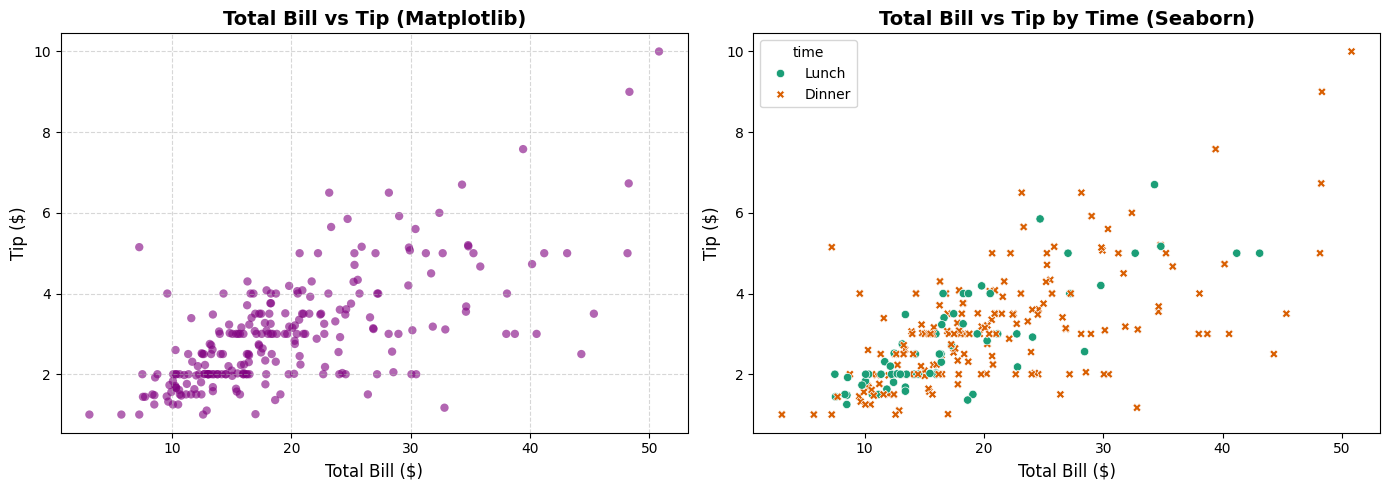

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Matplotlib
axes[0].scatter(tips['total_bill'], tips['tip'], color='purple', alpha=0.6, edgecolors='none')
axes[0].set_title('Total Bill vs Tip (Matplotlib)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Total Bill ($)', fontsize=12)
axes[0].set_ylabel('Tip ($)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Seaborn
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='time', style='time', palette='Dark2', ax=axes[1])
axes[1].set_title('Total Bill vs Tip by Time (Seaborn)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Bill ($)', fontsize=12)
axes[1].set_ylabel('Tip ($)', fontsize=12)

plt.tight_layout()
plt.show()

Grafik correlation_heatmap.png berhasil disimpan!


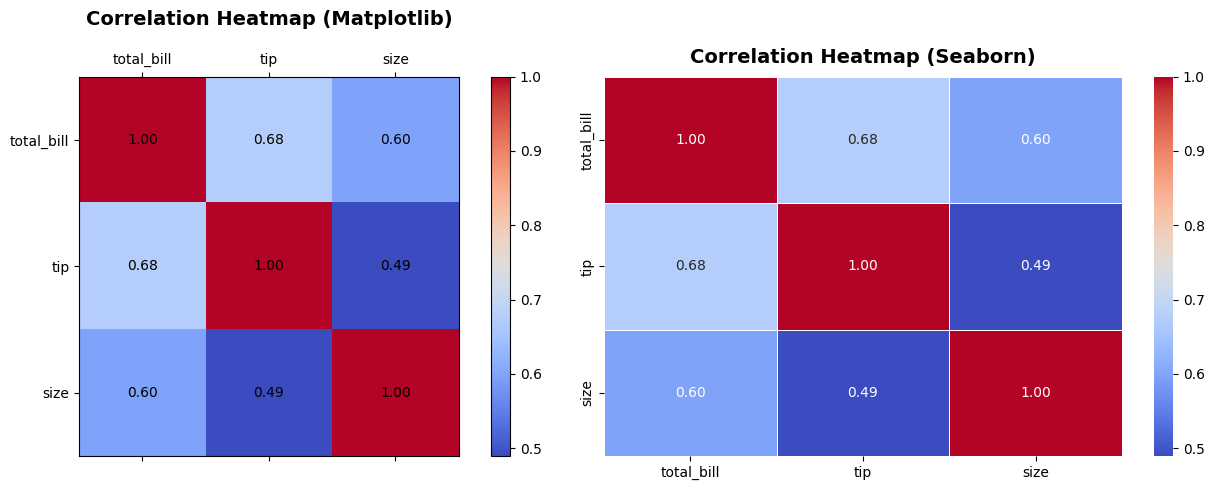

In [ ]:
# Hitung korelasi variabel numerik
numeric_tips = tips.select_dtypes(include=['float64', 'int64'])
corr_matrix = numeric_tips.corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Matplotlib (imshow)
cax = axes[0].matshow(corr_matrix, cmap='coolwarm')
fig.colorbar(cax, ax=axes[0])
axes[0].set_xticks(range(len(corr_matrix.columns)))
axes[0].set_yticks(range(len(corr_matrix.columns)))
axes[0].set_xticklabels(corr_matrix.columns)
axes[0].set_yticklabels(corr_matrix.columns)
axes[0].set_title('Correlation Heatmap (Matplotlib)', fontsize=14, fontweight='bold', pad=20)

# Tambahkan nilai angka pada cell Matplotlib
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        axes[0].text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha='center', va='center', color='black')

# 2. Seaborn (heatmap)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, ax=axes[1])
axes[1].set_title('Correlation Heatmap (Seaborn)', fontsize=14, fontweight='bold', pad=10)

plt.tight_layout()

# Menyimpan grafik sebagai file PNG (Syarat Project)
plt.savefig('correlation_heatmap.png', dpi=300, bbox_inches='tight')
print("Grafik correlation_heatmap.png berhasil disimpan!")

plt.show()